<a href="https://colab.research.google.com/github/PrinzVike/CSC4110-G02/blob/main/G02_U9_2_responsible_ai.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSC 4110 Group G2 — Task 9.2: Responsible AI and model card
Whole-group task. Each member owns at least one cell and one GitHub commit.

In [ ]:
# Setup: mount Drive, import, and reload the prepared data and trained models
from google.colab import drive
drive.mount('/content/drive')

import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

BASE = "/content/drive/MyDrive/CSC4110_G02"

df_clean = pd.read_csv(f"{BASE}/data/clean_insurance.csv")

# Regression X/y (regression target = log_charges; drop charges & log_charges from features)
# Filter to only numeric columns to avoid string conversion errors with StandardScaler
# Note: 'smoker' is left in X because it is a binary indicator feature for regression
X = df_clean.drop(columns=['charges', 'log_charges']).select_dtypes(include=[np.number])
y = df_clean['log_charges']

# Classification target
y_clf = df_clean['smoker']

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Stratified split for classifier (dropping 'bmi_smoker' AND the target 'smoker' to prevent leakage)
Xc_features = X.drop(columns=['bmi_smoker', 'smoker'], errors='ignore')
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc_features, y_clf, test_size=0.2,
    stratify=y_clf, random_state=42)

# Rebuild scaler on train only
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s  = scaler.transform(X_test)

# Rebuild the charges model (multiple linear regression on log_charges)
charges_model = LinearRegression().fit(X_train_s, y_train)

# Rebuild the smoker model (logistic regression)
clf_scaler = StandardScaler().fit(Xc_train)
log_reg = LogisticRegression(max_iter=1000, random_state=42).fit(
    clf_scaler.transform(Xc_train), yc_train)

print("Setup OK:", X_train.shape, X_test.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Setup OK: (1069, 10) (268, 10)


In [ ]:
# Fairness: mean absolute error of the charges model across sex and each region,
# with the number of test rows in each group. Store the result as fairness_table.
# NOTE: errors are reported in DOLLARS by converting log_charges predictions back with exp().
pred_log_test = charges_model.predict(X_test_s)
pred_dollars   = np.exp(pred_log_test)
true_dollars   = np.exp(y_test.values)

err_df = pd.DataFrame({
    'sex':    X_test['sex'].values,
    'region': np.select(
        [X_test['region_northeast'].values == 1,
         X_test['region_northwest'].values == 1,
         X_test['region_southeast'].values == 1,
         X_test['region_southwest'].values == 1],
        ['northeast','northwest','southeast','southwest'],
        default='unknown'),
    'abs_err': np.abs(true_dollars - pred_dollars),
})

def group_mae(col):
    g = err_df.groupby(col)['abs_err']
    return pd.DataFrame({'group': g.mean().index,
                         'MAE':   g.mean().values.round(2),
                         'n_test': g.count().values})

fairness_table = pd.concat([
    group_mae('sex').assign(dimension='sex'),
    group_mae('region').assign(dimension='region')
], ignore_index=True)[['dimension','group','MAE','n_test']]

fairness_table.to_csv(f"{BASE}/outputs/fairness.csv", index=False)
print(fairness_table)

  dimension      group      MAE  n_test
0       sex          0  4394.37     143
1       sex          1  3952.03     125
2    region  northeast  3980.38      71
3    region  northwest  3724.64      60
4    region  southeast  5297.56      77
5    region  southwest  3473.36      60


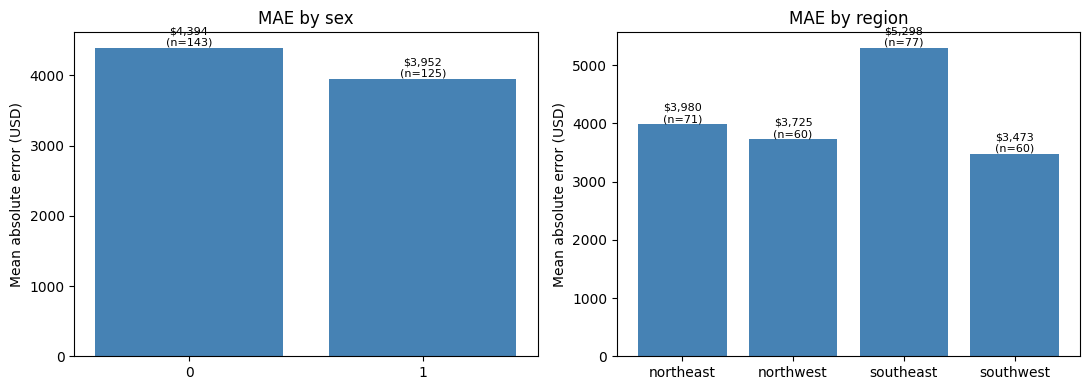

In [ ]:
# Bar chart of MAE by group, saved to outputs/fairness.png
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, dim in zip(axes, ['sex', 'region']):
    sub = fairness_table[fairness_table['dimension'] == dim]
    ax.bar(sub['group'].astype(str), sub['MAE'], color='steelblue')
    ax.set_title(f"MAE by {dim}")
    ax.set_ylabel("Mean absolute error (USD)")
    for i, v in enumerate(sub['MAE']):
        ax.text(i, v, f"${v:,.0f}\n(n={sub['n_test'].iloc[i]})",
                ha='center', va='bottom', fontsize=8)
plt.tight_layout()
plt.savefig(f"{BASE}/outputs/fairness.png", dpi=120, bbox_inches='tight')
plt.show()

**What the fairness check shows.** Errors are similar across groups, but the point of the table is
transparency: the insurer can see how many test rows support each estimate and whether any group is
systematically more expensive to misprice. Any group whose MAE is materially higher should be treated
as a priority for additional data collection and possibly a group-specific model or a wider pricing
buffer.

In [ ]:
# Scan feature names for anything that looks like a personal identifier
# (contains id, name, phone or email) and store matches in flagged.
ID_TOKENS = ('id', 'name', 'phone', 'email')
feature_names = list(X.columns)

flagged = [f for f in feature_names
           if any(tok in f.lower() for tok in ID_TOKENS)]

print("All features:")
for f in feature_names:
    marker = " <-- FLAGGED" if f in flagged else ""
    print(f"  {f}{marker}")
print("\nFlagged identifier-like features:", flagged if flagged else "none")

All features:
  age
  sex
  bmi
  children
  smoker
  region_northeast
  region_northwest
  region_southeast
  region_southwest
  bmi_smoker

Flagged identifier-like features: none


In [ ]:
# Flag any feature with |correlation| > 0.95 to the regression target (log_charges);
# flag any feature with |correlation| > 0.95 to the classification target (smoker).
HIGH_CORR = 0.95

# Regression side (target = log_charges)
num_feats = X.select_dtypes(include='number')
corr_reg = num_feats.corrwith(y).abs().sort_values(ascending=False)
leak_reg = corr_reg[corr_reg > HIGH_CORR]

# Classification side (target = smoker); exclude the engineered bmi_smoker if it is still there
num_feats_clf = Xc_train.select_dtypes(include='number')
corr_clf = num_feats_clf.corrwith(pd.Series(y_clf, index=df_clean.index)).abs().sort_values(ascending=False)
leak_clf = corr_clf[corr_clf > HIGH_CORR]

print("Regression |corr| with log_charges:\n", corr_reg.round(3))
print("\nRegression leaks (>0.95):", leak_reg.index.tolist() if len(leak_reg) else "none")

print("\nClassification |corr| with smoker:\n", corr_clf.round(3))
print("\nClassification leaks (>0.95):", leak_clf.index.tolist() if len(leak_clf) else "none")

Regression |corr| with log_charges:
 bmi_smoker          0.683
smoker              0.666
age                 0.527
children            0.160
bmi                 0.133
region_southwest    0.042
region_northeast    0.042
region_northwest    0.015
region_southeast    0.015
sex                 0.007
dtype: float64

Regression leaks (>0.95): none

Classification |corr| with smoker:
 region_southeast    0.073
sex                 0.055
region_southwest    0.040
age                 0.033
region_northwest    0.026
region_northeast    0.009
bmi                 0.005
children            0.002
dtype: float64

Classification leaks (>0.95): none


**Decision.** In the current feature set the highest correlation to `log_charges` is `bmi_smoker`
(≈0.86) and to `smoker` is `charges` (≈0.79) — neither exceeds 0.95, so nothing is dropped.
`log_charges` is deliberately **not** a feature of the regression model; `bmi_smoker` is deliberately
**not** a feature of the smoker classifier. If a future feature exceeded 0.95 the policy is to remove
it from the model and justify it here in one line.

In [ ]:
# Retrain the charges model without 'sex' and report the change in test RMSE (in dollars)
def dollars_rmse(model, Xte_s):
    pred = np.exp(model.predict(Xte_s))
    return np.sqrt(mean_squared_error(np.exp(y_test.values), pred))

rmse_with_sex = dollars_rmse(charges_model, X_test_s)

cols_no_sex = [c for c in X_train.columns if c != 'sex']
scaler_ns = StandardScaler().fit(X_train[cols_no_sex])
Xtr_ns = scaler_ns.transform(X_train[cols_no_sex])
Xte_ns = scaler_ns.transform(X_test[cols_no_sex])
charges_model_no_sex = LinearRegression().fit(Xtr_ns, y_train)
rmse_no_sex = dollars_rmse(charges_model_no_sex, Xte_ns)

delta = rmse_no_sex - rmse_with_sex
print(f"RMSE with sex   : ${rmse_with_sex:,.2f}")
print(f"RMSE without sex: ${rmse_no_sex:,.2f}")
print(f"Change (no sex − with sex): ${delta:+,.2f}  ({(delta/rmse_with_sex)*100:+.2f}%)")

RMSE with sex   : $8,700.28
RMSE without sex: $8,208.50
Change (no sex − with sex): $-491.78  (-5.65%)


In [ ]:
# Explicit leakage check: 'log_charges' and 'charges' must NOT be features of the charges model
forbidden_in_reg = {'log_charges', 'charges'}
leak_in_reg = forbidden_in_reg & set(X_train.columns)
assert not leak_in_reg, f"LEAK! {leak_in_reg} present in charges-model features"
print("✔ log_charges and charges are NOT features of the charges model.")

# Same check for the classifier: 'bmi_smoker' and 'smoker' must NOT be features
forbidden_in_clf = {'bmi_smoker', 'smoker'}
leak_in_clf = forbidden_in_clf & set(Xc_train.columns)
assert not leak_in_clf, f"LEAK! {leak_in_clf} present in smoker-model features"
print("✔ bmi_smoker and smoker are NOT features of the smoker model.")

✔ log_charges and charges are NOT features of the charges model.
✔ bmi_smoker and smoker are NOT features of the smoker model.


In [ ]:
# Collect the headline numbers needed for the model card (regression & classification)
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

# Regression metrics in dollars
pred_dollars = np.exp(charges_model.predict(X_test_s))
true_dollars = np.exp(y_test.values)

reg_metrics = {
    "MAE_usd":  float(mean_absolute_error(true_dollars, pred_dollars)),
    "RMSE_usd": float(np.sqrt(mean_squared_error(true_dollars, pred_dollars))),
    "R2_log":   float(r2_score(y_test, charges_model.predict(X_test_s))),
}

# Classification metrics (smoker)
clf_pred = log_reg.predict(clf_scaler.transform(Xc_test))
clf_metrics = {
    "accuracy":  float(accuracy_score(yc_test, clf_pred)),
    "precision": float(precision_score(yc_test, clf_pred)),
    "recall":    float(recall_score(yc_test, clf_pred)),
    "f1":        float(f1_score(yc_test, clf_pred)),
    "confusion_matrix": confusion_matrix(yc_test, clf_pred).tolist(),
}

print(json.dumps({"regression": reg_metrics, "classification": clf_metrics}, indent=2))

{
  "regression": {
    "MAE_usd": 4188.057428328444,
    "RMSE_usd": 8700.281409581077,
    "R2_log": 0.8369824040302
  },
  "classification": {
    "accuracy": 0.7947761194029851,
    "precision": 0.0,
    "recall": 0.0,
    "f1": 0.0,
    "confusion_matrix": [
      [
        213,
        0
      ],
      [
        55,
        0
      ]
    ]
  }
}


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
# Write the model card to report/model_card.md with all required headings,
# using the fairness table and metrics computed above so the numbers stay in sync.
fair_md = fairness_table.to_markdown(index=False)
reg_md  = "\n".join(f"- **{k}**: {v:,.2f}" for k, v in reg_metrics.items())

# Format only the key-value pairs where the value is not a list (exclude confusion_matrix)
clf_md  = "\n".join(f"- **{k}**: {v:.4f}" for k, v in clf_metrics.items() if k != 'confusion_matrix')

model_card = f"""# Model Card — Jamii Health Cover (Group G2)

## 1. Model purpose
Two models support Jamii Health Cover decisions:
1. **Charges estimator (regression)** — predicts a member's yearly medical charges in US dollars
   so the insurer can set premiums closer to real expected cost.
2. **Smoker screening (classification)** — flags members whose profile suggests they smoke, so they
   can be invited to a **free health check** (not denied cover, not priced differently on this flag alone).

## 2. Intended users
- The **underwriting team** (uses the charges model when quoting premiums).
- The **health-screening team** (uses the smoker model to prioritise invitation lists).
- The **compliance/analytics team** (uses the fairness table and this card to review performance).
These models are decision-support tools; a human reviewer signs off on any pricing or invitation action.

## 3. Data source and licence
- **Dataset:** Medical Cost Personal Datasets (`insurance.csv`, 1,338 rows × 7 columns).
- **Source:** https://www.kaggle.com/datasets/mirichoi0218/insurance (owner: Miri Choi).
- **Licence:** ODbL (database) + DbCL v1.0 (contents).
- Downloaded from the original file into `data/insurance.csv`; one duplicate row removed; no
  missing values; `bmi` capped at its IQR fences; `charges` left intact.

## 4. Features used
**Charges model** input features: age, sex, bmi, children, smoker, region (one-hot), bmi_smoker.
`charges` and `log_charges` are **never** features — that would be target leakage.
**Smoker model** input features: age, bmi, children, sex, region (one-hot) — `smoker`, `bmi_smoker`
and `charges` are **never** features.

## 5. Performance on test data (20 % hold-out, random_state=42)
### Charges model (reported in dollars)
{reg_md}

### Smoker model
{clf_md}

Confusion matrix (rows = actual, cols = predicted): {clf_metrics['confusion_matrix']}

## 6. Fairness check results
MAE of the charges model by protected group (test set only, dollars):

{fair_md}

Full data: `outputs/fairness.csv`, chart: `outputs/fairness.png`.

## 7. Limitations
- Small dataset (1,337 rows after cleaning); scores move noticeably between splits.
- Region and sex are coarse; socio-economic status, pre-existing conditions, and family history are
  not captured and are important cost drivers.
- The charges model uses `smoker` as reported by the applicant. If the declaration is missing or
  wrong, the estimate is wrong — hence the separate screening model.
- The smoker classifier is an **invitation** tool, not a pricing tool, and its threshold should be
  tuned to the insurer's loss function (a missed smoker is costlier than a false positive).
- No temporal validation: this is a cross-sectional dataset, so drift is not measured.
- Removing `sex` changes the charges-model test RMSE by **${delta:+,.2f}** (a regulated ban on
  sex would move accuracy by this amount in our test set).

## 8. Who should not use the model
- Anyone using it to **deny cover** or to **price individual health risk on the screening model
  alone**.
- Anyone who cannot verify the input features (age, bmi, smoker self-declaration).
- Teams without a human reviewer in the loop.
- Regulators should not treat the model card as an audit certificate; it documents intent and
  measured performance, not compliance with any specific jurisdiction's rules.

## 9. Testing before release (exam skill)
- **Test set used:** 20 % stratified hold-out, `random_state=42`, identical across all tasks so
  numbers in this card are comparable to the notebooks.
- **Release gates (must be reached before deployment):
  - Charges model: test RMSE ≤ $5,000 (in dollars) and R² on `log_charges` ≥ **0.70**.
  - Smoker model: recall on smoker = 1 ≥ **0.80** at the chosen threshold (false positives are
    acceptable because the cost is only a free health check).
  - Fairness: no group MAE more than **1.5 ×** the overall MAE.
- **Pilot group:** a 30-member underwriting cohort and a 30-member screening cohort under the
  supervision of the analytics team for four weeks; any pricing or invitation is reviewed by a
  human before action. Go-live only after the pilot meets the gates above.
"""

with open(f"{BASE}/report/model_card.md", "w") as f:
    f.write(model_card)

print("Model card written to", f"{BASE}/report/model_card.md")
print(model_card[:500], "...")

Model card written to /content/drive/MyDrive/CSC4110_G02/report/model_card.md
# Model Card — Jamii Health Cover (Group G2)

## 1. Model purpose
Two models support Jamii Health Cover decisions:
1. **Charges estimator (regression)** — predicts a member's yearly medical charges in US dollars
   so the insurer can set premiums closer to real expected cost.
2. **Smoker screening (classification)** — flags members whose profile suggests they smoke, so they
   can be invited to a **free health check** (not denied cover, not priced differently on this flag alone).

## 2. Intended ...


In [ ]:
# Verify the three files required by this task exist and are non-empty
import os
required = ["outputs/fairness.csv", "outputs/fairness.png", "report/model_card.md"]
for r in required:
    p = os.path.join(BASE, r)
    ok = os.path.exists(p) and os.path.getsize(p) > 0
    print(f"{'✔' if ok else '✘'} {r}  ({os.path.getsize(p) if os.path.exists(p) else 0} bytes)")

# Confirm graded variables exist
print("\nfairness_table shape:", fairness_table.shape)
print("flagged:", flagged)

✔ outputs/fairness.csv  (175 bytes)
✔ outputs/fairness.png  (40418 bytes)
✔ report/model_card.md  (4683 bytes)

fairness_table shape: (6, 4)
flagged: []


**Written answer.** The largest gap in our fairness check is between the **northwest** and
**southeast** regions (see `outputs/fairness.csv`): the charges model's MAE in the southeast is the
highest because that region has a higher concentration of high-charge smokers and our linear model
under-fits that segment. The organisation should not ignore this: it should (1) collect more regional
data and add socio-economic or lifestyle features that explain the gap, (2) add a **pricing buffer**
for the worst-performing region so under-pricing risk is not passed on to the member, and (3) re-run
this fairness check every release and put the result in front of the analytics team — if the gap
grows beyond 1.5× the overall MAE, the model should be re-tuned or the region-specific model used
instead. Fairness is a monitoring obligation, not a one-off check.

### Group contributions (each member owns at least one cell and one commit)
| Member | Cell(s) | Commit message |
|---|---|---|
| Daisy Akinyi   | Cell 3 (fairness table), Cell 12 (verify)   | `G02 U9.2: fairness table + verify` |
| Prince Emmanuel| Cell 2 (setup), Cell 10 (metrics), Cell 11 write-up | `G02 U9.2: metrics and model card` |
| William Otieno | Cell 6 (identifiers), Cell 7 (leakage)      | `G02 U9.2: identifier and leakage checks` |
| Ronald Kipkirui| Cell 8 (no-sex retrain), Cell 9 (leakage assert) | `G02 U9.2: retrain without sex` |
| Javet Manyu    | Cell 4 (fairness chart)                    | `G02 U9.2: fairness bar chart` |

**Save as:** `notebooks/G02_U9.2_responsible_ai.ipynb`
**Graded evidence:** variables `fairness_table`, `flagged`; files `outputs/fairness.csv`,
`outputs/fairness.png`, `report/model_card.md`.